### KDD · Fase 3: Transformación

Creación de una variable derivada y codificación de las variables categóricas.

- **Entradas:** `kdd/data/interim/train_clean.csv`, `kdd/data/interim/test_clean.csv`
- **Salidas:**
  - `kdd/data/processed/train_transformed.csv`, `kdd/data/processed/test_transformed.csv`: datos transformados
  - `kdd/models/encoder.joblib`: codificador ajustado
  - `kdd/figures/transformation_culmen_ratio.png`: variable derivada por especie

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
for folder in [PROCESSED_DIR, MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [3]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [4]:
train = pd.read_csv(INTERIM_DIR / "train_clean.csv")
test = pd.read_csv(INTERIM_DIR / "test_clean.csv")

TARGET = "species"
NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]

print(f"Entrenamiento: {train.shape} | Prueba: {test.shape}")

Entrenamiento: (273, 8) | Prueba: (69, 8)


#### Variable derivada: `culmen_ratio`

Cociente entre la longitud y la profundidad del culmen, que describe la forma del pico.

In [5]:
def add_culmen_ratio(df):
    df["culmen_ratio"] = (df["culmen_length_mm"] / df["culmen_depth_mm"]).round(4)
    return df


train = add_culmen_ratio(train)
test = add_culmen_ratio(test)
NUMERIC = NUMERIC + ["culmen_ratio"]

train.groupby(TARGET)["culmen_ratio"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,121.0,2.118,0.149,1.640,2.016,2.129,2.229,2.434
Chinstrap,54.0,2.636,0.149,2.350,2.541,2.624,2.701,3.258
Gentoo,98.0,3.174,0.177,2.566,3.065,3.171,3.287,3.613


#### `culmen_ratio` por especie

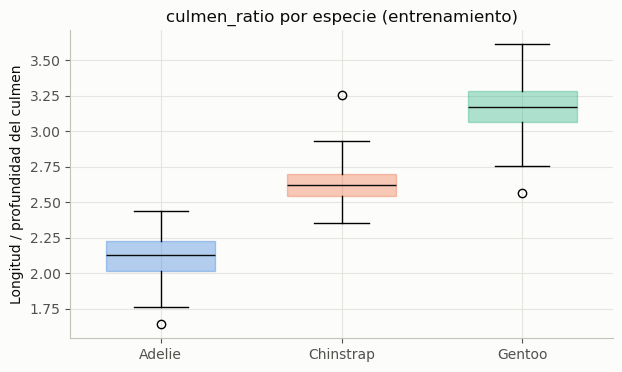

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

data = [train.loc[train[TARGET] == sp, "culmen_ratio"] for sp in SPECIES]
box = ax.boxplot(data, patch_artist=True, widths=0.6)
ax.set_xticks(range(1, len(SPECIES) + 1), SPECIES)
for patch, sp in zip(box["boxes"], SPECIES):
    patch.set_facecolor(COLORS[sp])
    patch.set_alpha(0.35)
    patch.set_edgecolor(COLORS[sp])
for median in box["medians"]:
    median.set_color("#0b0b0b")
ax.set_ylabel("Longitud / profundidad del culmen")
ax.set_title("culmen_ratio por especie (entrenamiento)")
fig.savefig(FIGURES_DIR / "transformation_culmen_ratio.png")
plt.show()

#### Codificación one-hot

El codificador se ajusta solo con el grupo de entrenamiento. Random Forest no requiere escalar las variables numéricas.

In [7]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[CATEGORICAL])

encoded_cols = encoder.get_feature_names_out(CATEGORICAL).tolist()
print(f"Columnas codificadas: {encoded_cols}")

Columnas codificadas: ['island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE', 'sex_UNKNOWN']


#### Aplicación de la transformación

In [8]:
def transform(df):
    encoded = pd.DataFrame(encoder.transform(df[CATEGORICAL]), columns=encoded_cols, index=df.index)
    return pd.concat([df[["row_id", TARGET] + NUMERIC], encoded.astype(int)], axis=1)


train_transformed = transform(train)
test_transformed = transform(test)

print(f"Entrenamiento: {train_transformed.shape} | Prueba: {test_transformed.shape}")
train_transformed.head()

Entrenamiento: (273, 13) | Prueba: (69, 13)


,row_id,species,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,culmen_ratio,island_Biscoe,island_Dream,island_Torgersen,sex_FEMALE,sex_MALE,sex_UNKNOWN
0,193,Chinstrap,46.2,17.5,187.0,3650.0,2.6400,0,1,0,1,0,0
1,98,Adelie,33.1,16.1,178.0,2900.0,2.0559,0,1,0,1,0,0
2,155,Chinstrap,45.4,18.7,188.0,3525.0,2.4278,0,1,0,1,0,0
3,40,Adelie,36.5,18.0,182.0,3150.0,2.0278,0,1,0,1,0,0
4,281,Gentoo,46.2,14.9,221.0,5300.0,3.1007,1,0,0,0,1,0


#### Verificación de la transformación

In [9]:
assert train_transformed.isna().sum().sum() == 0
assert test_transformed.isna().sum().sum() == 0
assert (train_transformed[encoded_cols].sum(axis=1) == len(CATEGORICAL)).all()
assert (test_transformed[encoded_cols].sum(axis=1) == len(CATEGORICAL)).all()
print("Sin valores faltantes y una categoría activa por variable en ambos grupos.")

Sin valores faltantes y una categoría activa por variable en ambos grupos.


#### Guardado de resultados

In [10]:
train_transformed.to_csv(PROCESSED_DIR / "train_transformed.csv", index=False)
test_transformed.to_csv(PROCESSED_DIR / "test_transformed.csv", index=False)
joblib.dump(encoder, MODELS_DIR / "encoder.joblib")

for path in [
    PROCESSED_DIR / "train_transformed.csv",
    PROCESSED_DIR / "test_transformed.csv",
    MODELS_DIR / "encoder.joblib",
    FIGURES_DIR / "transformation_culmen_ratio.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\train_transformed.csv
Guardado: ..\data\processed\test_transformed.csv
Guardado: ..\models\encoder.joblib
Guardado: ..\figures\transformation_culmen_ratio.png
